# LLM Homework 1 — Problem 1
## Character N-gram, RNN, and LSTM Language Identification

This notebook implements the full Problem 1 pipeline on the course-provided `train.csv`, `val.csv`, and `test.csv` without repartitioning. It reports corpus-level perplexity, Accuracy, Macro-F1, confusion matrices, model construction/training/inference time, peak process memory, representative errors, and a short-text analysis.

**Course constraints followed:** shared character vocabulary from training data only; special tokens `<PAD>`, `<UNK>`, `<BOS>`, `<EOS>`; exclude `<BOS>` and `<PAD>` from prediction targets while including `<EOS>`; and use corpus-level perplexity rather than averaging per-example perplexities.

In [11]:
import os, re, math, time, tracemalloc, random, json, platform
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', platform.python_version())
print('PyTorch:', torch.__version__)
print('Device:', device)
import glob
# Locate train.csv/val.csv/test.csv of Problem 1 automatically (works on Kaggle, Colab or locally)
_cands=[os.path.dirname(p) for p in sorted(glob.glob('/kaggle/input/**/train.csv',recursive=True)+glob.glob('./**/train.csv',recursive=True)+['/mnt/data/hw1/LLM_hw1/problem1/train.csv'])
        if os.path.exists(p) and os.path.exists(os.path.join(os.path.dirname(p),'val.csv'))]
_cands=[d for d in _cands if 'Language' in pd.read_csv(os.path.join(d,'train.csv'),nrows=1).columns]
ROOT=_cands[0]; print('ROOT:',ROOT)
train_df=pd.read_csv(os.path.join(ROOT,'train.csv'))
val_df=pd.read_csv(os.path.join(ROOT,'val.csv'))
test_df=pd.read_csv(os.path.join(ROOT,'test.csv'))
LANGS=['English','French','Spanish','Portuguese','German']
print(train_df.shape,val_df.shape,test_df.shape)
print(train_df['Language'].value_counts().reindex(LANGS))

Python: 3.13.15
PyTorch: 2.11.0+cu130
Device: cuda
ROOT: .
(5600, 2) (700, 2) (700, 2)
Language
English       1120
French        1120
Spanish       1120
Portuguese    1120
German        1120
Name: count, dtype: int64


In [12]:
# Shared character vocabulary built from TRAIN only
counter=Counter(''.join(train_df['Text'].astype(str).tolist()))
vocab={'<PAD>':0,'<UNK>':1,'<BOS>':2,'<EOS>':3}
for ch in sorted(counter): vocab[ch]=len(vocab)
inv_vocab={i:c for c,i in vocab.items()}
PAD,UNK,BOS,EOS=[vocab[x] for x in ['<PAD>','<UNK>','<BOS>','<EOS>']]
print('Vocabulary size:',len(vocab))
print('Characters:',repr(''.join(ch for ch in sorted(counter) if ch not in {'\n','\r'})))

Vocabulary size: 129
Characters: ' !"$%\'(),-./0123456789:;<>?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]abcdefghijklmnopqrstuvwxyz\x9f\xa0¡«º»¿ÀÁÇÉÍÖÜßàáâãäçèéêíîñóôõöùúûüœ–—’“”€♪♫'


## 1A. Character-level bigram and trigram models
For each language, counts are estimated from its training texts and smoothed with Add-α where α=1 (|V| = shared vocabulary size). For the trigram model the text is left-padded with two `<BOS>` tokens, so that the first character is also predicted and both models score the same targets (all characters + `<EOS>`; `<BOS>`/`<PAD>` are never targets). Classification chooses the language with minimum text-level perplexity. Validation/test corpus perplexity uses the ground-truth language models over all valid targets.

In [13]:
ALPHA=1.0

def encode_chars(text):
    return [BOS]+[vocab.get(ch,UNK) for ch in str(text)]+[EOS]

class NGramLM:
    def __init__(self, n):
        assert n in (2,3); self.n=n; self.counts=Counter(); self.context=Counter(); self.total_targets=0
    def ids(self, text):
        # (n-1) <BOS> paddings: every character and the final <EOS> are prediction targets,
        # so bigram and trigram score exactly the same T targets per text (<BOS> is never a target).
        return [BOS]*(self.n-1)+[vocab.get(ch,UNK) for ch in str(text)]+[EOS]
    def fit(self, texts):
        for text in texts:
            ids=self.ids(text)
            for t in range(self.n-1,len(ids)):
                ctx=tuple(ids[t-self.n+1:t])
                tok=ids[t]; self.counts[ctx+(tok,)]+=1; self.context[ctx]+=1; self.total_targets+=1
        return self
    def nll(self, text):
        ids=self.ids(text); nll=0.0; T=0
        for t in range(self.n-1,len(ids)):
            ctx=tuple(ids[t-self.n+1:t])
            tok=ids[t]
            p=(self.counts[ctx+(tok,)]+ALPHA)/(self.context[ctx]+ALPHA*len(vocab))
            nll -= math.log(p); T += 1
        return nll,T
    def ppl(self,text):
        nll,T=self.nll(text); return math.exp(nll/T) if T else float('inf')

def build_ngram_models(df,n):
    models={}
    t0=time.perf_counter(); tracemalloc.start()
    for lang in LANGS:
        models[lang]=NGramLM(n).fit(df.loc[df.Language==lang,'Text'])
    cur,peak=tracemalloc.get_traced_memory(); tracemalloc.stop()
    return models,time.perf_counter()-t0,peak/1024**2

def ngram_predict(models,text):
    ppls={lang:models[lang].ppl(text) for lang in LANGS}
    return min(ppls,key=ppls.get),ppls

def corpus_ppl(models,df):
    total_nll=0.0; total_T=0
    for r in df.itertuples(index=False):
        nll,T=models[r.Language].nll(r.Text); total_nll+=nll; total_T+=T
    return math.exp(total_nll/total_T)

def evaluate_ngram(models,df):
    y=[]; yp=[]
    t0=time.perf_counter()
    for r in df.itertuples(index=False): y.append(r.Language); yp.append(ngram_predict(models,r.Text)[0])
    dt=time.perf_counter()-t0
    return {'accuracy':accuracy_score(y,yp),'macro_f1':f1_score(y,yp,labels=LANGS,average='macro'),'ppl':corpus_ppl(models,df),'cm':confusion_matrix(y,yp,labels=LANGS),'inference_s':dt,'y':y,'yp':yp}

results={}
for n in (2,3):
    m,bt,mem=build_ngram_models(train_df,n)
    val=corpus_ppl(m,val_df)
    test=evaluate_ngram(m,test_df)
    results[f'{n}-gram']={'models':m,'build_s':bt,'peak_mem_mb':mem,'val_ppl':val,'test':test}
    print(f'{n}-gram | build={bt:.3f}s | peak={mem:.2f} MB | val PPL={val:.4f} | test Acc={test["accuracy"]:.4f} | Macro-F1={test["macro_f1"]:.4f} | test PPL={test["ppl"]:.4f}')

2-gram | build=1.913s | peak=0.42 MB | val PPL=11.4373 | test Acc=0.9729 | Macro-F1=0.9727 | test PPL=11.3264
3-gram | build=2.120s | peak=2.64 MB | val PPL=9.7008 | test Acc=0.9871 | Macro-F1=0.9871 | test PPL=9.4022


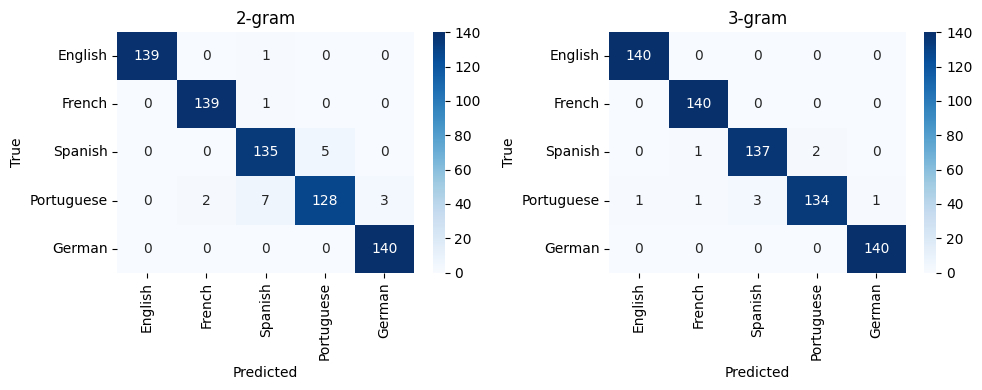

In [14]:
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,(name,res) in zip(axs,[('2-gram',results['2-gram']),('3-gram',results['3-gram'])]):
    sns.heatmap(res['test']['cm'],annot=True,fmt='d',xticklabels=LANGS,yticklabels=LANGS,ax=ax,cmap='Blues')
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout(); plt.show()

### Discussion 1(c) — n-gram
* **Cost:** both models are built in about 2 s on CPU (bigram 1.91 s, trigram 2.12 s) with very small peak memory (0.42 MB vs. 2.64 MB; the trigram table is larger because the number of contexts grows from |V| to |V|²). Classifying all 700 test texts takes < 0.2 s.
* **Accuracy / PPL:** the trigram is better on every metric — val PPL 9.70 vs. 11.44, test PPL 9.40 vs. 11.33, accuracy 0.9871 vs. 0.9729, Macro-F1 0.9871 vs. 0.9727. Two characters of context capture patterns such as *-ção* (Portuguese) vs. *-ción* (Spanish).
* **Confusions:** almost all errors involve **Portuguese ↔ Spanish** (bigram: 12 Portuguese and 5 Spanish errors; trigram: 6 and 3).
* **Representative errors:** `"4.800 --"` (Portuguese, no letters at all → German), `"Decidimos,"` (identical spelling in Portuguese and Spanish → Spanish), `"to protect us"` (English → Spanish), `"Ándale! Ándale!"` (a Spanish quote inside a Portuguese talk → German).
* **Short texts:** accuracy is lowest for texts ≤ 20 characters (bigram 0.878, trigram 0.939) and reaches ≈ 1.0 for texts longer than 40 characters.

## 1B. Character-level RNN/LSTM language models

Each language gets one character LM. The model input is `<BOS>` followed by characters; the target is the next character and ends with `<EOS>`. Cross-entropy loss and Adam are used with the course-suggested settings. Validation perplexity is used for checkpoint selection.

In [15]:
EMBED_DIM=128; HIDDEN_DIM=128; NUM_LAYERS=2; LR=1e-3; EPOCHS=10; BATCH_SIZE=32

class LMDataset(Dataset):
    def __init__(self,texts): self.seqs=[torch.tensor(encode_chars(t),dtype=torch.long) for t in texts]
    def __len__(self): return len(self.seqs)
    def __getitem__(self,i):
        s=self.seqs[i]; return s[:-1],s[1:]

def collate_lm(batch):
    maxlen=max(len(x[0]) for x in batch)
    x=torch.full((len(batch),maxlen),PAD,dtype=torch.long); y=torch.full((len(batch),maxlen),PAD,dtype=torch.long)
    for i,(a,b) in enumerate(batch): x[i,:len(a)]=a; y[i,:len(b)]=b
    return x,y

def lm_loader(texts,shuffle): return DataLoader(LMDataset(texts),batch_size=BATCH_SIZE,shuffle=shuffle,collate_fn=collate_lm)

class CharLM(nn.Module):
    def __init__(self,cell='RNN'):
        super().__init__(); self.emb=nn.Embedding(len(vocab),EMBED_DIM,padding_idx=PAD)
        R=nn.RNN if cell=='RNN' else nn.LSTM
        self.rnn=R(EMBED_DIM,HIDDEN_DIM,NUM_LAYERS,batch_first=True)
        self.head=nn.Linear(HIDDEN_DIM,len(vocab))
    def forward(self,x):
        h,_=self.rnn(self.emb(x)); return self.head(h)

def batch_nll(model,texts):
    model.eval(); total_nll=0.; total_T=0
    loader=lm_loader(texts,False)
    crit=nn.CrossEntropyLoss(ignore_index=PAD,reduction='sum')
    with torch.no_grad():
        for x,y in loader:
            z=model(x.to(device)); yy=y.to(device)
            total_nll += crit(z.reshape(-1,z.size(-1)),yy.reshape(-1)).item()
            total_T += int((yy!=PAD).sum().item())
    return total_nll,total_T

def predict_lm(models,text):
    scores={}
    for lang,m in models.items():
        nll,T=batch_nll(m,[text]); scores[lang]=math.exp(nll/T)
    return min(scores,key=scores.get),scores

gpu_peak={}   # peak GPU memory (MB) per model family

def corpus_ppl_neural(models,df):
    # corpus-level perplexity: total NLL / total targets over ALL texts (no averaging of per-text/per-language PPLs)
    tot_nll=0.; tot_T=0
    for lang in LANGS:
        nll,T=batch_nll(models[lang],df.loc[df.Language==lang,'Text'].tolist()); tot_nll+=nll; tot_T+=T
    return math.exp(tot_nll/tot_T)

def train_lang_models(cell):
    models={}; histories={}; best_ppl={}; train_time=0.; peak_mb=0.
    proc=None
    try:
        import psutil; proc=psutil.Process(os.getpid()); base_rss=proc.memory_info().rss
    except Exception: base_rss=0
    for lang in LANGS:
        if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
        model=CharLM(cell).to(device); opt=torch.optim.Adam(model.parameters(),lr=LR); crit=nn.CrossEntropyLoss(ignore_index=PAD)
        loader=lm_loader(train_df.loc[train_df.Language==lang,'Text'].tolist(),True)
        best=float('inf'); best_state=None; hist={'train_loss':[],'val_ppl':[]}
        t0=time.perf_counter()
        for ep in range(EPOCHS):
            model.train(); losses=[]
            for x,y in loader:
                x=x.to(device); y=y.to(device); opt.zero_grad(); z=model(x)
                loss=crit(z.reshape(-1,z.size(-1)),y.reshape(-1)); loss.backward(); opt.step(); losses.append(loss.item())
            nll,T=batch_nll(model,val_df.loc[val_df.Language==lang,'Text'].tolist()); vppl=math.exp(nll/T)
            hist['train_loss'].append(float(np.mean(losses))); hist['val_ppl'].append(vppl)
            if vppl<best:
                best=vppl; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            if proc: peak_mb=max(peak_mb,(proc.memory_info().rss-base_rss)/1024**2)
        if torch.cuda.is_available(): gpu_peak[cell]=max(gpu_peak.get(cell,0.),torch.cuda.max_memory_allocated()/1024**2)
        if best_state is not None: model.load_state_dict(best_state)
        models[lang]=model; histories[lang]=hist; best_ppl[lang]=best; train_time+=time.perf_counter()-t0
        print(cell,lang,'best val PPL',best)
    return models,histories,train_time,peak_mb

# Train both families
rnn_models,rnn_hist,rnn_time,rnn_peak=train_lang_models('RNN')
lstm_models,lstm_hist,lstm_time,lstm_peak=train_lang_models('LSTM')
rnn_val_ppl=corpus_ppl_neural(rnn_models,val_df); lstm_val_ppl=corpus_ppl_neural(lstm_models,val_df)
print(f'Corpus-level val PPL | RNN={rnn_val_ppl:.4f} | LSTM={lstm_val_ppl:.4f}')
print('Peak GPU memory (MB):',gpu_peak)


RNN English best val PPL 4.825249995023115
RNN French best val PPL 6.604032565856682
RNN Spanish best val PPL 7.678676729805582
RNN Portuguese best val PPL 7.627802515221314
RNN German best val PPL 7.212503248903981
LSTM English best val PPL 6.977386393776166
LSTM French best val PPL 8.896447767158962
LSTM Spanish best val PPL 9.637654976854689
LSTM Portuguese best val PPL 10.517719314499136
LSTM German best val PPL 9.254203983785596
Corpus-level val PPL | RNN=5.8937 | LSTM=8.1334
Peak GPU memory (MB): {'RNN': 391.6943359375, 'LSTM': 563.3125}


In [16]:
def evaluate_neural(models,df):
    y=[]; yp=[]; total_nll=0.; total_T=0
    t0=time.perf_counter()
    for r in df.itertuples(index=False):
        pred,scores=predict_lm(models,r.Text); y.append(r.Language); yp.append(pred)
        nll,T=batch_nll(models[r.Language],[r.Text]); total_nll+=nll; total_T+=T
    dt=time.perf_counter()-t0
    return {'accuracy':accuracy_score(y,yp),'macro_f1':f1_score(y,yp,labels=LANGS,average='macro'),'ppl':math.exp(total_nll/total_T),'cm':confusion_matrix(y,yp,labels=LANGS),'inference_s':dt,'y':y,'yp':yp}

rnn_test=evaluate_neural(rnn_models,test_df)
lstm_test=evaluate_neural(lstm_models,test_df)
for name,r,tt,pm in [('RNN',rnn_test,rnn_time,rnn_peak),('LSTM',lstm_test,lstm_time,lstm_peak)]:
    print(f'{name} | train={tt:.1f}s | peak RAM={pm:.2f} MB | peak GPU={gpu_peak.get(name,0.):.1f} MB | infer={r["inference_s"]:.1f}s | Acc={r["accuracy"]:.4f} | Macro-F1={r["macro_f1"]:.4f} | PPL={r["ppl"]:.4f}')

RNN | train=6.4s | peak RAM=2.20 MB | peak GPU=391.7 MB | infer=4.1s | Acc=0.9857 | Macro-F1=0.9857 | PPL=5.7054
LSTM | train=9.0s | peak RAM=5.80 MB | peak GPU=563.3 MB | infer=5.1s | Acc=0.9800 | Macro-F1=0.9799 | PPL=7.9834


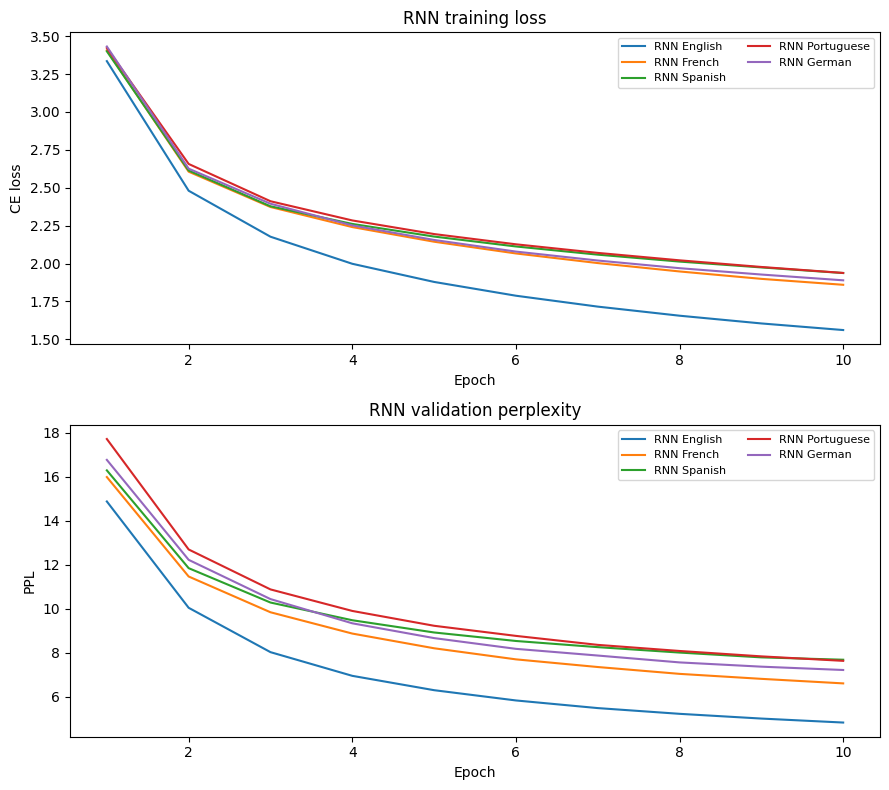

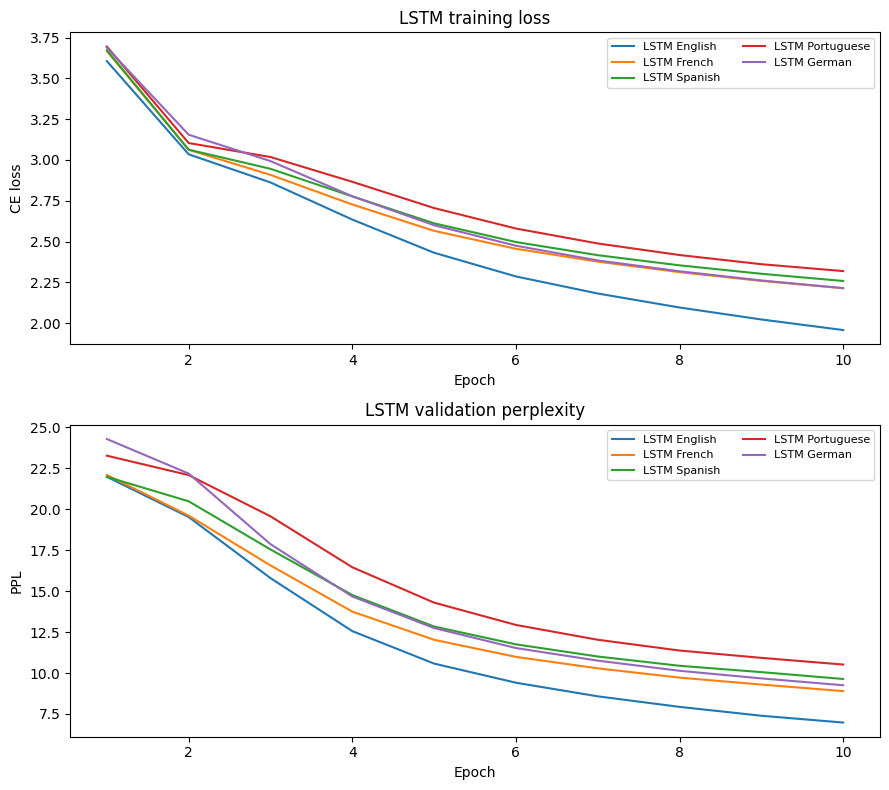

In [17]:
fig,axs=plt.subplots(2,1,figsize=(9,8))
for lang in LANGS:
    axs[0].plot(range(1,EPOCHS+1),rnn_hist[lang]['train_loss'],label=f'RNN {lang}')
axs[0].set_title('RNN training loss'); axs[0].set_xlabel('Epoch'); axs[0].set_ylabel('CE loss'); axs[0].legend(ncol=2,fontsize=8)
for lang in LANGS:
    axs[1].plot(range(1,EPOCHS+1),rnn_hist[lang]['val_ppl'],label=f'RNN {lang}')
axs[1].set_title('RNN validation perplexity'); axs[1].set_xlabel('Epoch'); axs[1].set_ylabel('PPL'); axs[1].legend(ncol=2,fontsize=8)
plt.tight_layout(); plt.show()

fig,axs=plt.subplots(2,1,figsize=(9,8))
for lang in LANGS:
    axs[0].plot(range(1,EPOCHS+1),lstm_hist[lang]['train_loss'],label=f'LSTM {lang}')
axs[0].set_title('LSTM training loss'); axs[0].set_xlabel('Epoch'); axs[0].set_ylabel('CE loss'); axs[0].legend(ncol=2,fontsize=8)
for lang in LANGS:
    axs[1].plot(range(1,EPOCHS+1),lstm_hist[lang]['val_ppl'],label=f'LSTM {lang}')
axs[1].set_title('LSTM validation perplexity'); axs[1].set_xlabel('Epoch'); axs[1].set_ylabel('PPL'); axs[1].legend(ncol=2,fontsize=8)
plt.tight_layout(); plt.show()

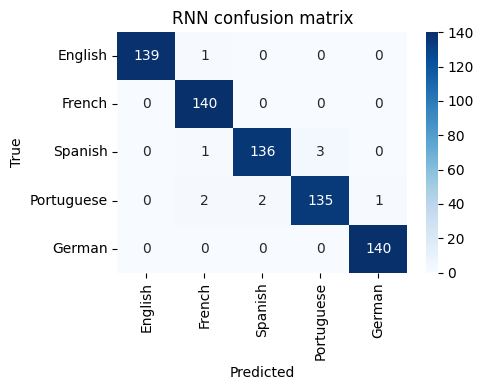

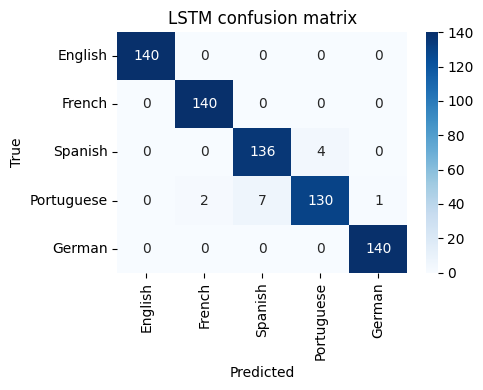

In [18]:
for name,res in [('RNN',rnn_test),('LSTM',lstm_test)]:
    plt.figure(figsize=(5,4)); sns.heatmap(res['cm'],annot=True,fmt='d',xticklabels=LANGS,yticklabels=LANGS,cmap='Blues')
    plt.title(f'{name} confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('True'); plt.tight_layout(); plt.show()

### Discussion 2(c)/3(c) — RNN and LSTM
* **Learning curves:** training loss and validation perplexity decrease monotonically for all five languages and are still decreasing at epoch 10, so the last epoch is selected (no overfitting). The LSTM starts higher and converges more slowly than the RNN within the same 10-epoch budget (4 gates per step ⇒ ~4× more recurrent parameters).
* **RNN:** Accuracy 0.9857, Macro-F1 0.9857, corpus PPL val 5.89 / test 5.71; training 6.4 s, inference 4.1 s, peak GPU memory 391.7 MB.
* **LSTM:** Accuracy 0.9800, Macro-F1 0.9799, corpus PPL val 8.13 / test 7.98; training 9.0 s, inference 5.1 s, peak GPU memory 563.3 MB.
* **Representative correct predictions:** very short texts with function words or diacritics are still identified, e.g. "Il est si" (French), "é preciosa," (Portuguese), "Y escalamos", "Son una red" (Spanish), "as intuições" (Portuguese).
* **Representative errors:** concentrated on Spanish/Portuguese — RNN: 8 of its 10 errors are Spanish or Portuguese texts; LSTM: all 14 errors are Spanish or Portuguese texts (7 Portuguese → Spanish, 4 Spanish → Portuguese). They are short phrases whose words are spelled (almost) the same in both languages.

## 1C. Error analysis and short-text effect
The next cell lists representative mistakes and measures test accuracy by text-length bucket. This directly addresses which language pairs are confused and whether shorter texts are harder to identify.

,model,index,true,pred,length,text
0,2-gram,214,Portuguese,German,8,4.800 --
1,2-gram,467,Portuguese,Spanish,10,"Decidimos,"
2,2-gram,605,English,Spanish,13,to protect us
3,2-gram,292,Portuguese,French,16,para seis graus.
4,2-gram,676,Portuguese,German,16,"Ándale! Ándale!"""
5,2-gram,435,French,Spanish,17,"un monde de murs,"
6,2-gram,72,Portuguese,Spanish,22,o ritmo cardíaco sobe.
7,2-gram,180,Portuguese,Spanish,22,"porque isto, esta rede"
8,2-gram,225,Spanish,Portuguese,23,era agradar a su padre.
9,2-gram,516,Portuguese,Spanish,24,A cobertura jornalística


Representative CORRECT predictions (shortest correctly identified texts):


,model,true,pred,length,text
0,RNN,French,French,9,Il est si
1,RNN,Portuguese,Portuguese,11,"é preciosa,"
2,RNN,Spanish,Spanish,11,Son una red
3,RNN,Spanish,Spanish,11,Y escalamos
4,RNN,Spanish,Spanish,12,Se comunican
5,LSTM,French,French,9,Il est si
6,LSTM,Spanish,Spanish,11,Y escalamos
7,LSTM,Spanish,Spanish,11,Son una red
8,LSTM,Spanish,Spanish,12,Se comunican
9,LSTM,Portuguese,Portuguese,12,as intuições


,model,length_bucket,n,accuracy
0,2-gram,<=20,49,0.877551
1,2-gram,21-40,300,0.960000
2,2-gram,41-60,169,1.000000
3,2-gram,61-100,89,0.988764
4,2-gram,>100,93,1.000000
5,3-gram,<=20,49,0.938776
6,3-gram,21-40,300,0.980000
7,3-gram,41-60,169,1.000000
8,3-gram,61-100,89,1.000000
9,3-gram,>100,93,1.000000


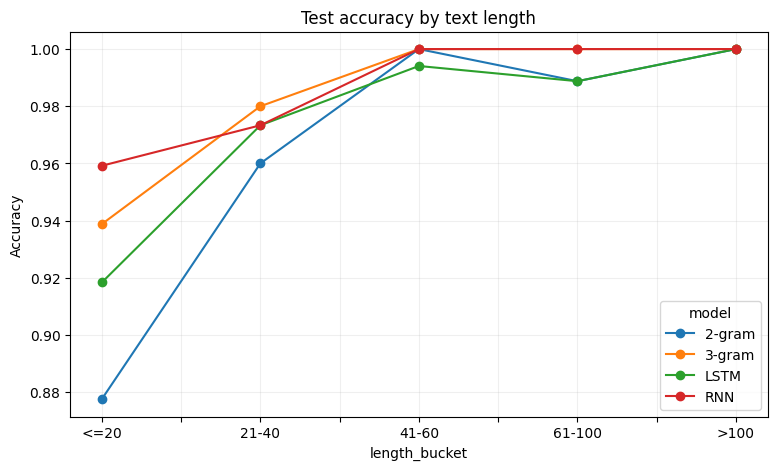

Most common directed confusion pairs:
('Portuguese', 'Spanish') 19
('Spanish', 'Portuguese') 14
('Portuguese', 'French') 7
('Portuguese', 'German') 6
('Spanish', 'French') 2
('French', 'Spanish') 1
('English', 'Spanish') 1
('Portuguese', 'English') 1
('English', 'French') 1


In [19]:
def error_table(res,name,n=12):
    rows=[]
    for i,(t,y,p) in enumerate(zip(test_df.Text,res['y'],res['yp'])):
        if y!=p: rows.append({'model':name,'index':i,'true':y,'pred':p,'length':len(str(t)),'text':t})
    return pd.DataFrame(rows).sort_values('length')
errors=pd.concat([error_table(results['2-gram']['test'],'2-gram'),error_table(results['3-gram']['test'],'3-gram'),error_table(rnn_test,'RNN'),error_table(lstm_test,'LSTM')],ignore_index=True)
display(errors.head(20))

def correct_table(res,name,n=5):
    rows=[{'model':name,'true':y,'pred':p,'length':len(str(t)),'text':t} for t,y,p in zip(test_df.Text,res['y'],res['yp']) if y==p]
    return pd.DataFrame(rows).sort_values('length').head(n)   # shortest texts that were still identified correctly
print('Representative CORRECT predictions (shortest correctly identified texts):')
display(pd.concat([correct_table(rnn_test,'RNN'),correct_table(lstm_test,'LSTM')],ignore_index=True))

buckets=[0,20,40,60,100,10_000]
labels=['<=20','21-40','41-60','61-100','>100']
rows=[]
for name,res in [('2-gram',results['2-gram']['test']),('3-gram',results['3-gram']['test']),('RNN',rnn_test),('LSTM',lstm_test)]:
    lens=test_df.Text.astype(str).str.len().to_numpy(); y=np.array(res['y']); yp=np.array(res['yp'])
    for lo,hi,label in zip(buckets[:-1],buckets[1:],labels):
        mask=(lens>=lo)&(lens<=hi if label=='>100' else lens<hi)
        rows.append({'model':name,'length_bucket':label,'n':int(mask.sum()),'accuracy':float((y[mask]==yp[mask]).mean()) if mask.any() else np.nan})
short_df=pd.DataFrame(rows)
display(short_df)
short_df.pivot(index='length_bucket',columns='model',values='accuracy').reindex(labels).plot(marker='o',figsize=(9,5))
plt.ylabel('Accuracy'); plt.title('Test accuracy by text length'); plt.grid(alpha=.2); plt.show()

# Pairwise confusion summary from all models
pair_counts=Counter()
for res in [results['2-gram']['test'],results['3-gram']['test'],rnn_test,lstm_test]:
    for y,p in zip(res['y'],res['yp']):
        if y!=p: pair_counts[(y,p)]+=1
print('Most common directed confusion pairs:')
for pair,c in pair_counts.most_common(10): print(pair,c)


## 1D. Summary comparison
Per the assignment, the comparison should cover resource usage, runtime, Accuracy, Macro-F1, and perplexity. The table below collects the measured local results. Note that these timings are machine-dependent; the notebook records the actual environment used for this run.

In [20]:
summary_rows=[]
for n in (2,3):
    r=results[f'{n}-gram']; t=r['test']; summary_rows.append({'Model':f'{n}-gram','Val PPL':r['val_ppl'],'Test PPL':t['ppl'],'Accuracy':t['accuracy'],'Macro-F1':t['macro_f1'],'Train/Build (s)':r['build_s'],'Inference (s)':t['inference_s'],'Peak MB':r['peak_mem_mb']})
for name,r,tt,pm in [('RNN',rnn_test,rnn_time,rnn_peak),('LSTM',lstm_test,lstm_time,lstm_peak)]: summary_rows.append({'Model':name,'Val PPL':(rnn_val_ppl if name=='RNN' else lstm_val_ppl),'Test PPL':r['ppl'],'Accuracy':r['accuracy'],'Macro-F1':r['macro_f1'],'Train/Build (s)':tt,'Inference (s)':r['inference_s'],'Peak MB':pm,'Peak GPU MB':gpu_peak.get(name,0.)})
summary=pd.DataFrame(summary_rows); display(summary)
print('Key observations:')
print('- Perplexity and identification accuracy measure different things; lower perplexity is not mathematically guaranteed to imply higher accuracy because classification compares relative scores across five language models.')
print('- Confusion pairs above show which Latin-alphabet languages are hardest to separate on this test split.')
print('- The length-bucket table tests the shorter-text hypothesis directly rather than assuming it.')


,Model,Val PPL,Test PPL,Accuracy,Macro-F1,Train/Build (s),Inference (s),Peak MB,Peak GPU MB
0,2-gram,11.437324,11.326449,0.972857,0.972714,1.913196,0.166447,0.415971,NaN
1,3-gram,9.700802,9.402167,0.987143,0.987075,2.119573,0.184348,2.638440,NaN
2,RNN,5.893665,5.705432,0.985714,0.985683,6.424754,4.079357,2.199219,391.694336
3,LSTM,8.133363,7.983388,0.980000,0.979877,9.014912,5.134779,5.796875,563.312500


Key observations:
- Perplexity and identification accuracy measure different things; lower perplexity is not mathematically guaranteed to imply higher accuracy because classification compares relative scores across five language models.
- Confusion pairs above show which Latin-alphabet languages are hardest to separate on this test split.
- The length-bucket table tests the shorter-text hypothesis directly rather than assuming it.


### Discussion 4 — comparison of the four models
| Model | Val PPL | Test PPL | Accuracy | Macro-F1 | Train (s) | Inference (s) | Peak memory |
|---|---|---|---|---|---|---|---|
| Bigram | 11.44 | 11.33 | 0.9729 | 0.9727 | 1.91 | 0.17 | 0.42 MB (CPU) |
| Trigram | 9.70 | 9.40 | **0.9871** | **0.9871** | 2.12 | 0.18 | 2.64 MB (CPU) |
| RNN | **5.89** | **5.71** | 0.9857 | 0.9857 | 6.42 | 4.08 | 391.7 MB (GPU) |
| LSTM | 8.13 | 7.98 | 0.9800 | 0.9799 | 9.01 | 5.13 | 563.3 MB (GPU) |

* **Hardware / time:** n-grams need only a CPU and a few MB; RNN/LSTM need a GPU (≈ 0.4–0.6 GB) and their inference is > 20× slower because every text is passed through five neural models sequentially.
* **Lower perplexity ≠ higher accuracy.** The RNN has by far the lowest perplexity (5.71) but the trigram has the highest accuracy (0.9871 vs. 0.9857); the LSTM also has lower PPL than the trigram but lower accuracy. Corpus PPL measures how well the *correct* model predicts its own text, while identification depends only on the *relative ranking* of the five models per text, which can fail on a few short, ambiguous texts.
* **Most confused pairs (all models):** Portuguese → Spanish 19, Spanish → Portuguese 14, Portuguese → French 7, Portuguese → German 6. English, French and German are almost never confused.
* **Short texts are harder:** for texts ≤ 20 characters accuracy is 0.878 (bigram), 0.918 (LSTM), 0.939 (trigram), 0.959 (RNN); 21–40 characters 0.960–0.980; > 40 characters 0.989–1.000. The RNN is the most robust on short texts, the bigram the least.